In [20]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

df = df.dropna(subset=['Hours_Studied', 'Exam_Score'])

print("Dataset loaded successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Saving StudentPerformanceFactors.csv to StudentPerformanceFactors (1).csv
Dataset loaded successfully!
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65     

In [14]:
X_simple = df[['Hours_Studied']]

X_multiple = df[
    ['Hours_Studied', 'Attendance', 'Previous_Scores']
]

y = df['Exam_Score']

In [15]:
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

In [16]:
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, simple_predictions)))


--- Simple Linear Regression ---
Intercept: 61.51116746904424
Coefficient: 0.285668744443087
R2 Score: 0.2319868674542106
RMSE: 3.294832513010839


In [17]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, multiple_predictions)))


--- Multiple Linear Regression ---
Intercept: 42.00637955940461
Coefficients: [0.28749797 0.19913445 0.04746368]
R2 Score: 0.6223383752199567
RMSE: 2.3104706093257077


In [18]:
new_student_simple = pd.DataFrame({
    "Hours_Studied": [6]
})

new_student_multiple = pd.DataFrame({
    "Hours_Studied": [6],
    "Attendance": [80],
    "Previous_Scores": [75]
})

print("\nPredicted marks using Simple Regression:",
      simple_model.predict(new_student_simple)[0])

print("Predicted marks using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])


Predicted marks using Simple Regression: 63.22517993570276
Predicted marks using Multiple Regression: 63.22189989226399


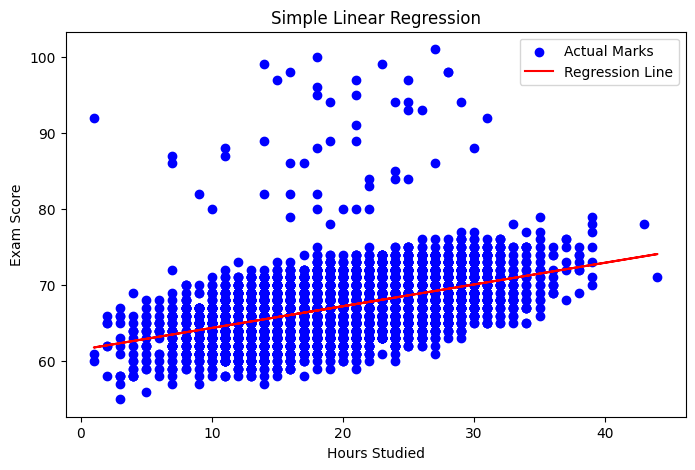

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Hours_Studied"],
    df["Exam_Score"],
    color="blue",
    label="Actual Marks"
)

plt.plot(
    df["Hours_Studied"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()